# 01 – Exploratory Data Analysis: Hotel Booking Demand

Goal: understand demand patterns before building the forecast model.

Questions:
1. How clean is the data?
2. How often do guests cancel, and what drives it?
3. How strong are the yearly and weekly patterns in rooms sold?
4. How does price (ADR) move with demand?

Data: `data/raw/hotel_bookings.csv` (119,390 bookings, Portugal, arrivals Jul 2015 – Aug 2017).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append(str(Path("..") / "src"))
from data_prep import build_daily, load_raw  # noqa: E402

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
HOTELS = ["City Hotel", "Resort Hotel"]
COLORS = {"City Hotel": "#1f77b4", "Resort Hotel": "#ff7f0e"}
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

raw = load_raw(Path("..") / "data" / "raw" / "hotel_bookings.csv")
print(raw.shape)
raw["hotel"].value_counts()

(119390, 34)


hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

## 1. Data quality

In [2]:
missing = raw.isna().sum()
print("Missing values:\n", missing[missing > 0].sort_values(ascending=False), "\n")
print("ADR <= 0      :", (raw["adr"] <= 0).sum())
print("ADR > 1000    :", (raw["adr"] > 1000).sum())
print("0-night stays :", (raw["total_nights"] == 0).sum())

Missing values:
 company     112593
agent        16340
country        488
children         4
dtype: int64 

ADR <= 0      : 1960
ADR > 1000    : 1
0-night stays : 715


`company` and `agent` are mostly empty (no company / no agent), so they are not used.
Rows with ADR ≤ 0, ADR > 1000 or 0 nights are removed in `data_prep.clean()`.

## 2. Cancellations

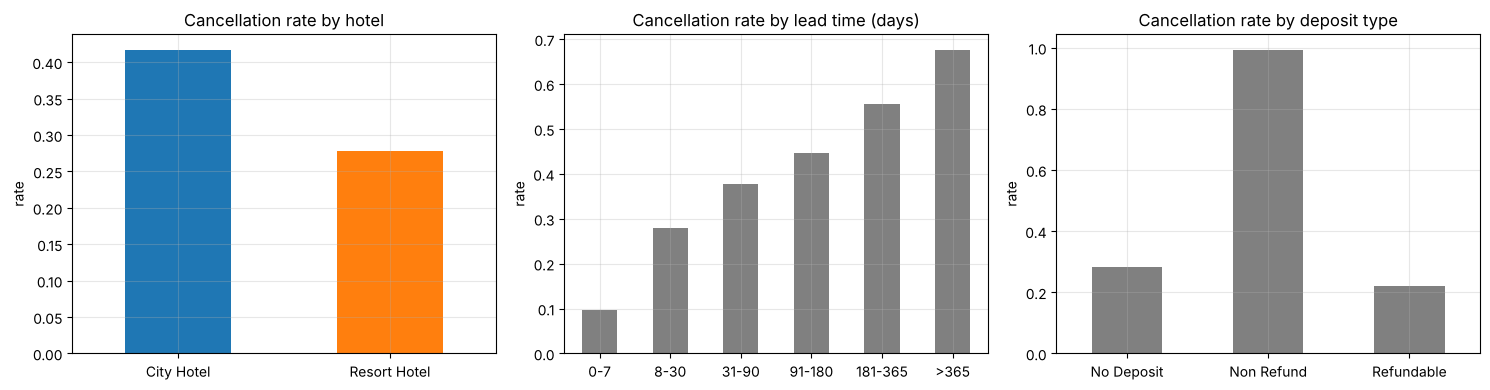

hotel
City Hotel      0.417
Resort Hotel    0.278
Name: is_canceled, dtype: float64
lead_bucket
0-7        0.096
8-30       0.279
31-90      0.377
91-180     0.447
181-365    0.555
>365       0.677
Name: is_canceled, dtype: float64
               mean    size
deposit_type               
No Deposit    0.284  104641
Non Refund    0.994   14587
Refundable    0.222     162


In [3]:
raw["lead_bucket"] = pd.cut(raw["lead_time"], [-1, 7, 30, 90, 180, 365, 1000],
                           labels=["0-7", "8-30", "31-90", "91-180", "181-365", ">365"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
raw.groupby("hotel")["is_canceled"].mean().plot.bar(ax=axes[0], color=[COLORS[h] for h in HOTELS])
axes[0].set_title("Cancellation rate by hotel")
raw.groupby("lead_bucket", observed=True)["is_canceled"].mean().plot.bar(ax=axes[1], color="gray")
axes[1].set_title("Cancellation rate by lead time (days)")
raw.groupby("deposit_type")["is_canceled"].mean().plot.bar(ax=axes[2], color="gray")
axes[2].set_title("Cancellation rate by deposit type")
for ax in axes:
    ax.set_ylabel("rate"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print(raw.groupby("hotel")["is_canceled"].mean().round(3))
print(raw.groupby("lead_bucket", observed=True)["is_canceled"].mean().round(3))
print(raw.groupby("deposit_type")["is_canceled"].agg(["mean", "size"]).round(3))

## 3. Daily rooms sold

Only non-canceled bookings count. Each booking = 1 room for every night of the stay.
For seasonal averages we use **Sep 2015 – Aug 2017** (exactly 2 full years), because the
first two months are incomplete for the City Hotel.

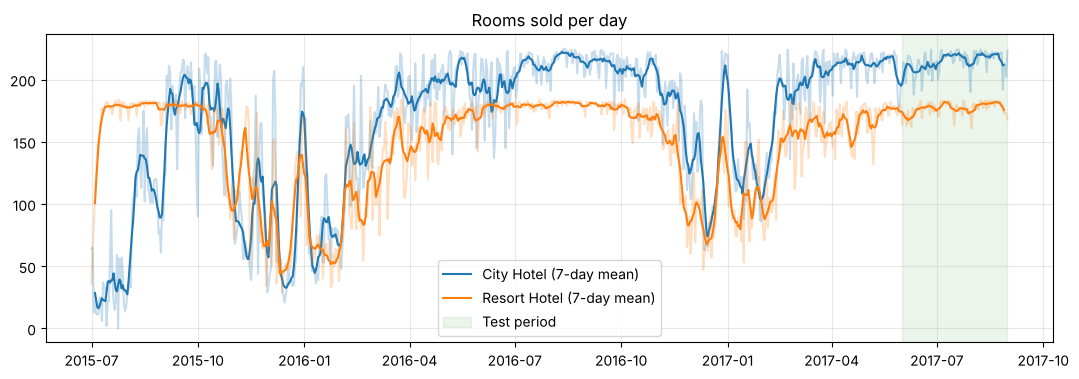

City Hotel: mean 176, max 225, days at >= 95% of max: 29%
Resort Hotel: mean 148, max 184, days at >= 95% of max: 40%


In [4]:
daily = {h: build_daily(raw, h, "2017-08-31") for h in HOTELS}

fig, ax = plt.subplots(figsize=(13, 4))
for h in HOTELS:
    s = daily[h]["rooms_sold"]
    ax.plot(s.index, s, color=COLORS[h], alpha=0.25)
    ax.plot(s.index, s.rolling(7, center=True).mean(), color=COLORS[h], label=f"{h} (7-day mean)")
ax.axvspan(pd.Timestamp("2017-06-01"), pd.Timestamp("2017-08-31"), color="green", alpha=0.08, label="Test period")
ax.set_title("Rooms sold per day"); ax.legend(); plt.show()

two_years = {h: d[(d.index >= "2015-09-01")] for h, d in daily.items()}
for h, d in two_years.items():
    print(f"{h}: mean {d['rooms_sold'].mean():.0f}, max {d['rooms_sold'].max()}, "
          f"days at >= 95% of max: {(d['rooms_sold'] >= 0.95 * d['rooms_sold'].max()).mean():.0%}")

### 3.1 Yearly and weekly patterns

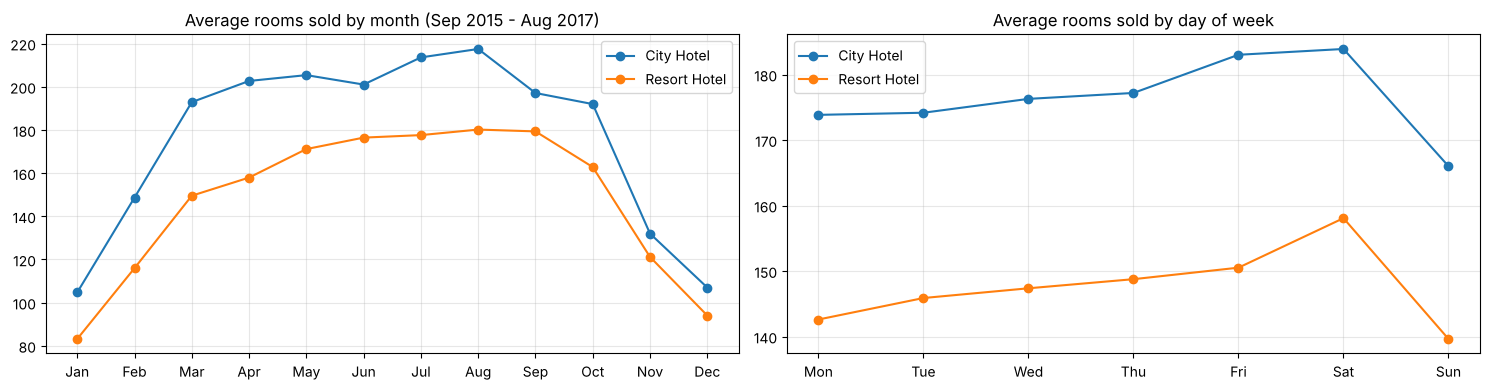

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
City Hotel,105.0,149.0,193.0,203.0,205.0,201.0,214.0,218.0,197.0,192.0,132.0,107.0
Resort Hotel,83.0,116.0,150.0,158.0,171.0,176.0,178.0,180.0,179.0,163.0,121.0,94.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for h, d in two_years.items():
    by_month = d.groupby(d.index.month)["rooms_sold"].mean()
    by_dow = d.groupby(d.index.dayofweek)["rooms_sold"].mean()
    axes[0].plot(MONTHS, by_month.values, marker="o", color=COLORS[h], label=h)
    axes[1].plot(DAYS, by_dow.values, marker="o", color=COLORS[h], label=h)
axes[0].set_title("Average rooms sold by month (Sep 2015 - Aug 2017)")
axes[1].set_title("Average rooms sold by day of week")
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

table = pd.DataFrame({h: d.groupby(d.index.month)["rooms_sold"].mean().round(0) for h, d in two_years.items()})
table.index = MONTHS
table.T

In [6]:
for h, d in two_years.items():
    by_dow = d.groupby(d.index.dayofweek)["rooms_sold"].mean()
    print(f"{h}: busiest day {DAYS[by_dow.idxmax()]} ({by_dow.max():.0f}), "
          f"quietest {DAYS[by_dow.idxmin()]} ({by_dow.min():.0f}), "
          f"gap {(by_dow.max() / by_dow.min() - 1):.0%}")

City Hotel: busiest day Sat (184), quietest Sun (166), gap 11%
Resort Hotel: busiest day Sat (158), quietest Sun (140), gap 13%


## 4. Price (ADR) and demand

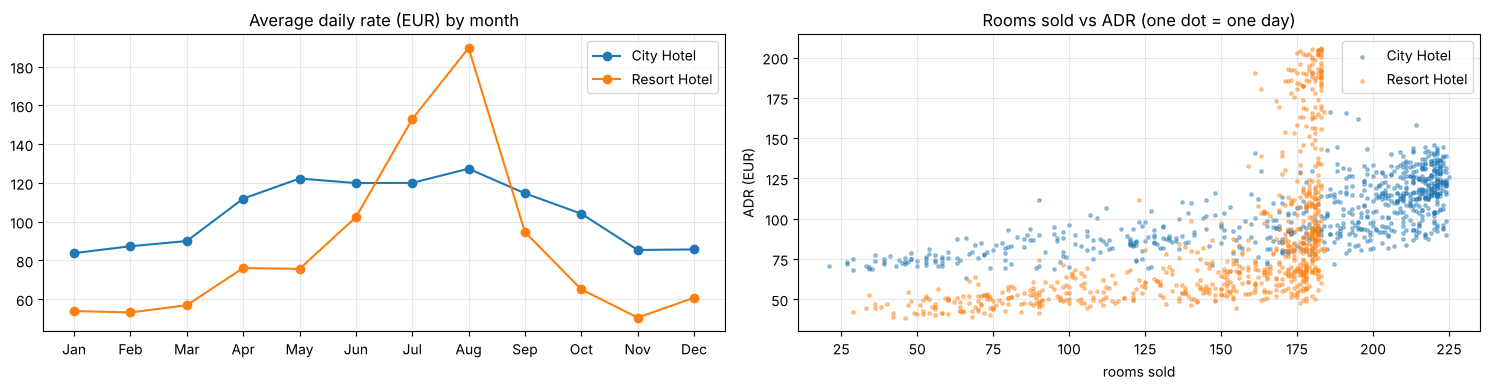

               Jan   Feb   Mar    Apr    May    Jun    Jul    Aug    Sep  \
City Hotel    84.0  87.0  90.0  112.0  122.0  120.0  120.0  127.0  115.0   
Resort Hotel  54.0  53.0  57.0   76.0   76.0  102.0  153.0  190.0   95.0   

                Oct   Nov   Dec  
City Hotel    104.0  85.0  86.0  
Resort Hotel   65.0  51.0  61.0  
City Hotel: correlation rooms sold vs ADR = 0.71
Resort Hotel: correlation rooms sold vs ADR = 0.55


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for h, d in two_years.items():
    by_month = d.groupby(d.index.month)["adr"].mean()
    axes[0].plot(MONTHS, by_month.values, marker="o", color=COLORS[h], label=h)
    axes[1].scatter(d["rooms_sold"], d["adr"], s=6, alpha=0.4, color=COLORS[h], label=h)
axes[0].set_title("Average daily rate (EUR) by month")
axes[1].set_title("Rooms sold vs ADR (one dot = one day)")
axes[1].set_xlabel("rooms sold"); axes[1].set_ylabel("ADR (EUR)")
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

adr_table = pd.DataFrame({h: d.groupby(d.index.month)["adr"].mean().round(0) for h, d in two_years.items()})
adr_table.index = MONTHS
print(adr_table.T)
for h, d in two_years.items():
    print(f"{h}: correlation rooms sold vs ADR = {d[['rooms_sold', 'adr']].corr().iloc[0, 1]:.2f}")

## Key findings

**Data quality**
- 119,390 bookings: 79,330 City Hotel, 40,060 Resort Hotel.
- `company` (94% empty) and `agent` (14% empty) are not used. 1,960 rows have ADR ≤ 0 and 715 have 0 nights; they are removed.
- City Hotel data looks incomplete in Jul–Aug 2015 (very low rooms sold), so seasonal averages use Sep 2015 – Aug 2017 and model training starts in Aug 2015.

**Cancellations**
- 42% of City Hotel bookings and 28% of Resort Hotel bookings are canceled. This is why only non-canceled bookings are counted as demand.
- The earlier the booking, the more likely it is canceled: 10% for 0–7 days of lead time, 68% for more than 1 year.
- "Non Refund" deposits show a 99% cancel rate. This looks like a data quirk (known for this dataset), not real guest behavior, so deposit type should be used with care.

**Demand patterns**
- Strong yearly cycle: City Hotel sells ~105 rooms/day in January vs ~218 in August; Resort Hotel ~83 vs ~180.
- Both hotels are often full in summer: the Resort Hotel is at ≥ 95% of its max on 40% of days, the City Hotel on 29%. In the test period (Jun–Aug 2017) both are near full, so forecast errors are small for every model.
- Weekly cycle is weaker: Saturday is the busiest day and Sunday the quietest (11–13% gap).

**Price vs demand**
- Busy months have higher prices. The Resort Hotel ADR goes from ~53 EUR in winter to ~190 EUR in August; the City Hotel moves less (84 → 127 EUR).
- Rooms sold and ADR are correlated (0.71 City, 0.55 Resort).
- When the Resort Hotel is full (~180 rooms), ADR still varies from ~70 to ~200 EUR. This supports the pricing idea in `pricing.py`: when the forecast says "full", the hotel can raise prices without losing guests.

**What this means for the model**
- Yearly features (`dayofyear`, `lag_364`) and the recent level (`lag_14`, rolling means) should matter most, which matches LightGBM's top features.
- Capacity limits make demand flat at the top in summer; a future step is to test the model on low-season periods too (rolling backtest).
